In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('/content/Wholesale customers data.csv')

In [ ]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

In [ ]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [ ]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

In [ ]:
df.shape

(440, 8)

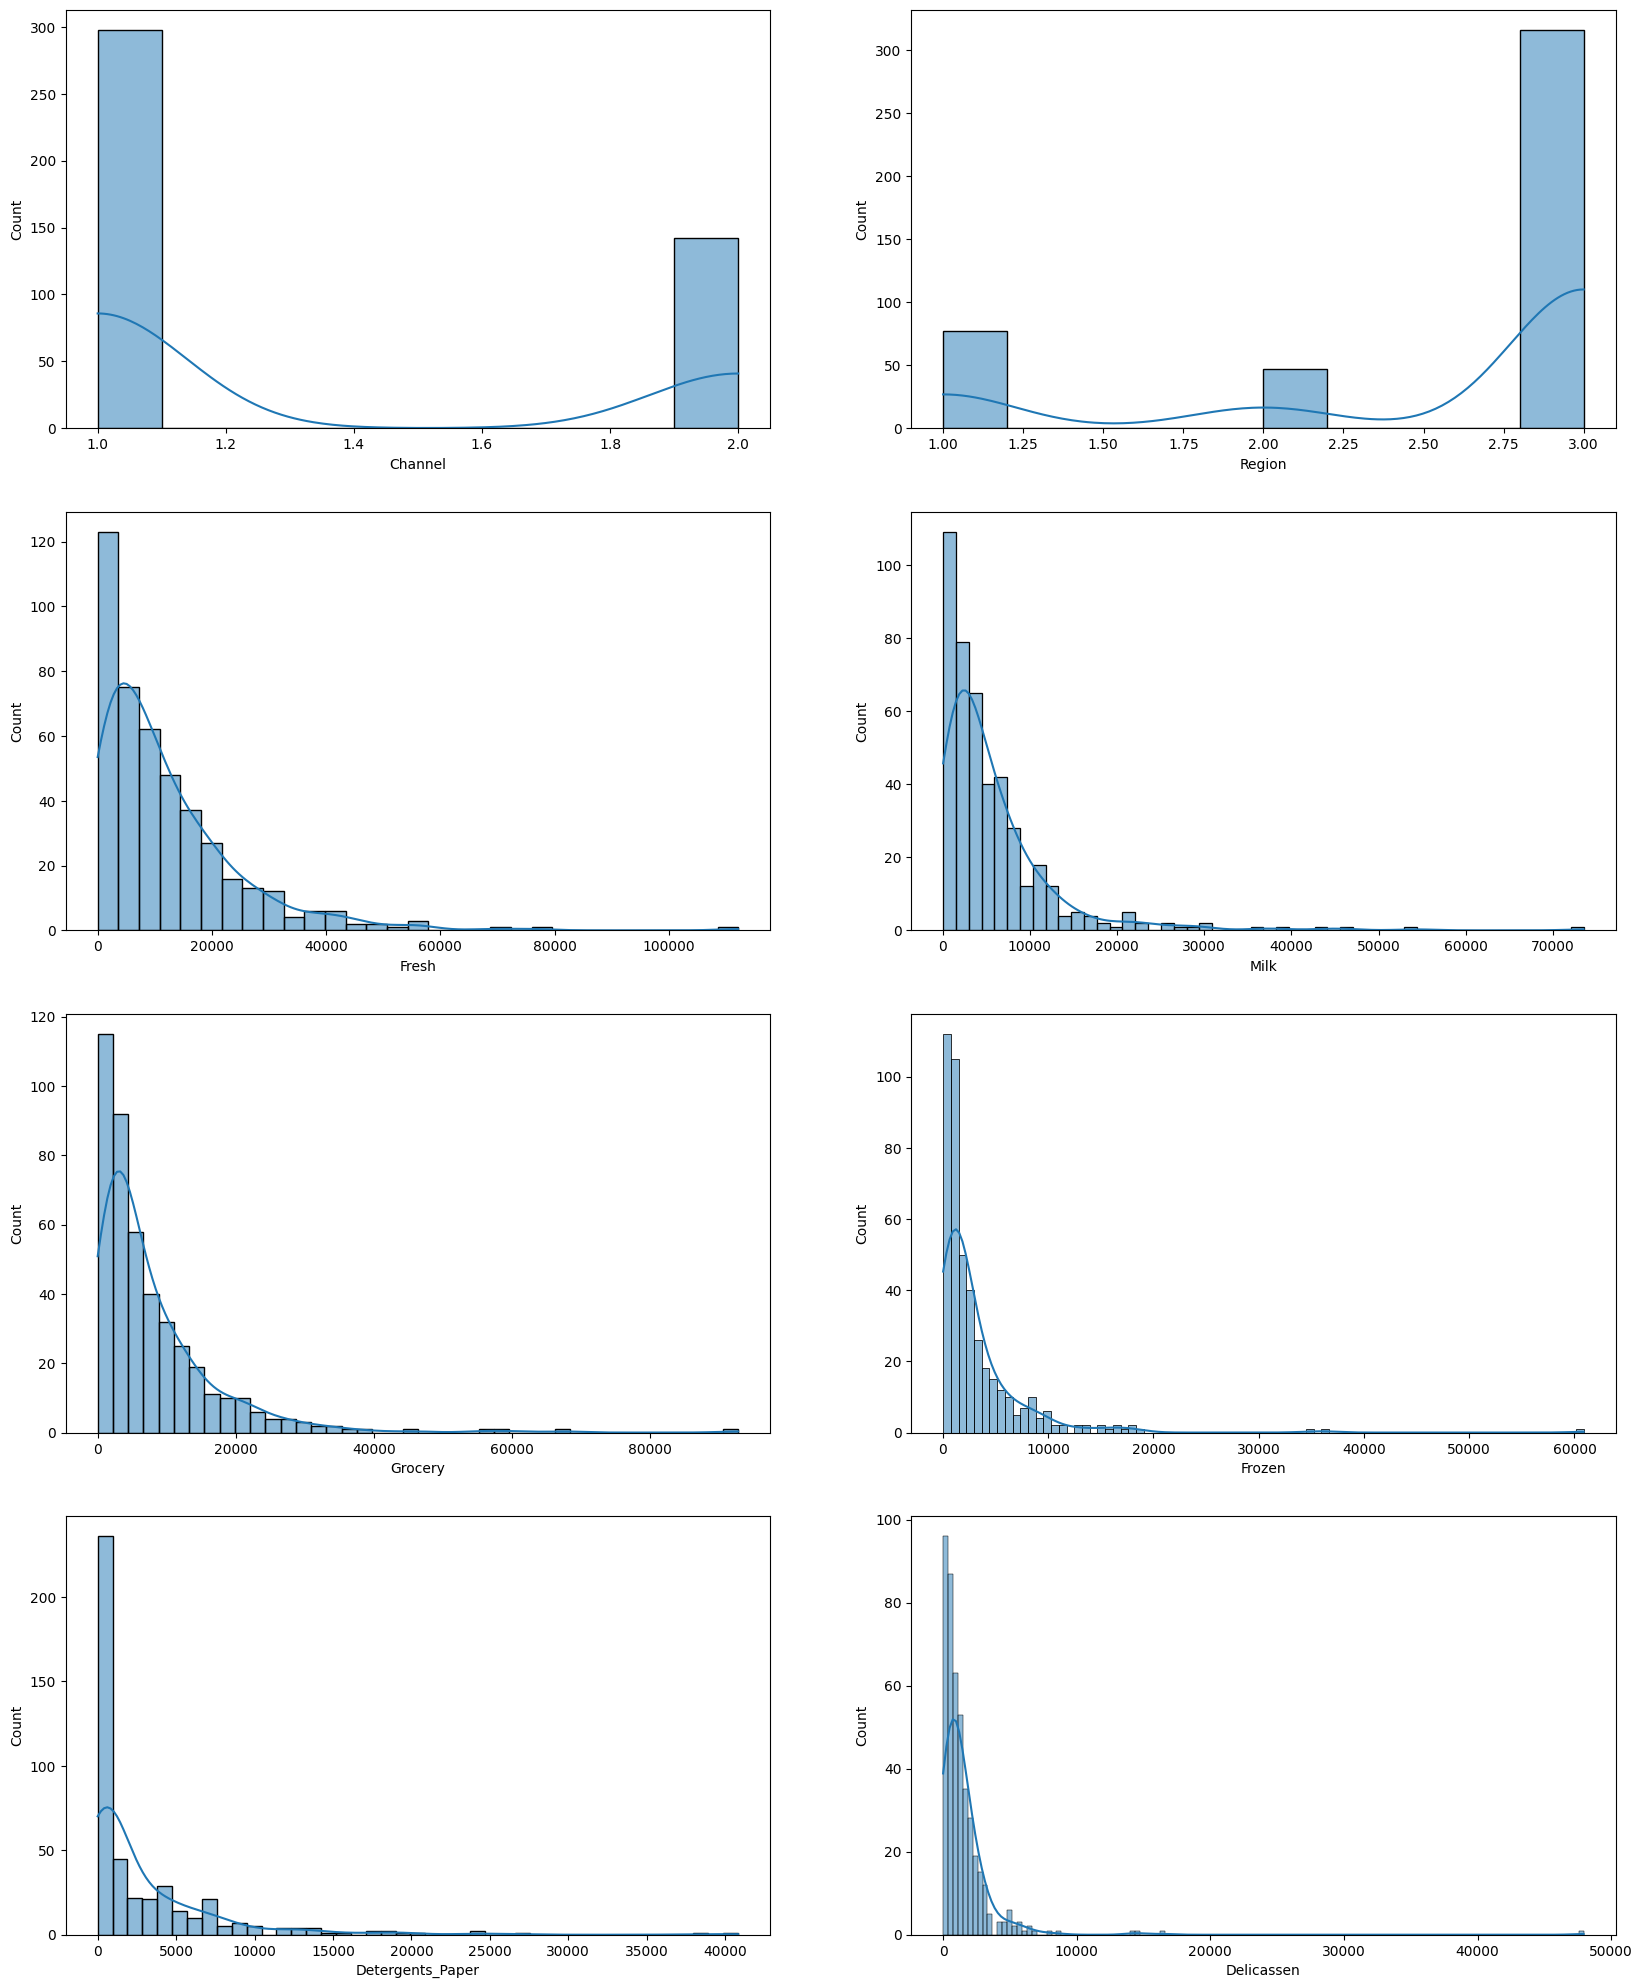

In [ ]:
figure=plt.figure(figsize=(20,25))
for i in range(0,8):
    plt.subplot(4,2,i+1)
    sns.histplot(df.iloc[:,i],kde=True)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df[['Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen']]=scaler.fit_transform(df[['Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen']])

In [ ]:
x=df[['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']]

In [ ]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

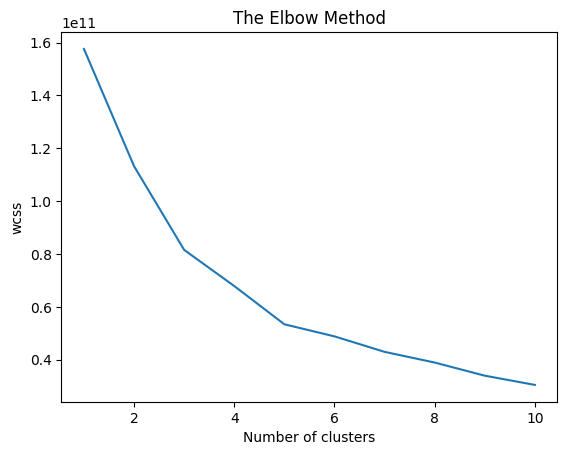

In [ ]:
from sklearn.cluster import KMeans
wcss=[]
for i in range(1,11):
  kmeans=KMeans(n_clusters=i,random_state=42)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)
plt.plot(range(1,11),wcss)
plt.title("The Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("wcss")
plt.show()

In [ ]:
from sklearn.cluster import KMeans
model=KMeans(n_clusters=5,random_state=42)
model.fit(x)

KMeans(n_clusters=5, random_state=42)

In [ ]:
label=model.labels_
label

array([4, 4, 4, 4, 1, 4, 4, 4, 4, 0, 0, 4, 1, 1, 1, 4, 0, 4, 1, 4, 1, 4,
       1, 2, 1, 1, 4, 4, 0, 1, 1, 4, 1, 1, 4, 0, 1, 0, 0, 3, 1, 1, 0, 0,
       4, 0, 0, 2, 4, 0, 4, 4, 1, 0, 1, 4, 0, 0, 4, 4, 4, 2, 4, 0, 4, 2,
       4, 1, 4, 4, 1, 1, 4, 1, 4, 1, 4, 0, 4, 4, 4, 0, 0, 1, 4, 2, 2, 3,
       4, 1, 4, 4, 2, 4, 0, 4, 4, 4, 4, 4, 0, 0, 4, 3, 4, 1, 0, 0, 4, 0,
       4, 0, 1, 4, 1, 4, 4, 4, 1, 4, 1, 4, 4, 4, 1, 3, 1, 1, 4, 1, 4, 4,
       4, 4, 4, 4, 4, 4, 4, 4, 1, 1, 1, 4, 1, 0, 4, 4, 4, 1, 1, 4, 1, 4,
       4, 0, 0, 1, 4, 0, 0, 4, 4, 0, 4, 0, 4, 4, 4, 4, 0, 0, 4, 0, 4, 0,
       3, 4, 4, 4, 4, 3, 0, 3, 4, 4, 4, 4, 0, 0, 1, 4, 4, 0, 4, 1, 1, 0,
       4, 4, 0, 0, 1, 4, 4, 0, 4, 4, 4, 0, 1, 2, 4, 4, 0, 0, 0, 1, 0, 4,
       4, 0, 4, 4, 4, 4, 1, 4, 4, 4, 4, 4, 1, 4, 1, 4, 4, 1, 4, 3, 1, 1,
       1, 4, 0, 0, 4, 4, 1, 4, 4, 2, 4, 1, 4, 1, 4, 4, 3, 3, 4, 4, 1, 4,
       0, 0, 0, 1, 0, 4, 4, 4, 4, 1, 4, 4, 1, 4, 4, 1, 4, 4, 3, 1, 3, 1,
       4, 1, 1, 1, 4, 4, 4, 0, 1, 4, 1, 4, 4, 4, 1,

In [ ]:
model.cluster_centers_

array([[ 4556.06976744, 11005.5       , 17461.87209302,  1388.46511628,
         7559.61627907,  1531.08139535],
       [23710.8490566 ,  3882.05660377,  5169.31132075,  3772.44339623,
         1118.26415094,  1693.10377358],
       [18192.4       , 35361.6       , 48052.2       ,  3308.4       ,
        23534.9       ,  4461.1       ],
       [56453.30769231, 10026.23076923,  8739.        , 15518.07692308,
         1258.23076923,  7170.53846154],
       [ 6485.07555556,  3148.57333333,  3798.95555556,  2655.75111111,
         1099.94666667,   986.54666667]])

In [ ]:
new_point=[[7000,6000,4000,5000,6000,7000]]
model.predict(new_point)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([4], dtype=int32)

In [ ]:
from sklearn.metrics import silhouette_score
score=silhouette_score(x,label)
score

np.float64(0.3763283247810499)

CONCLUSION:
The Elbow Method indicated 5 clusters. The silhouette score of 0.37 suggested moderate cluster separation, which is acceptable given the overlapping nature of customer purchasing behavior in the wholesale dataset.